# 03 - Processing Cloudy outputs with py4radiation

This tutorial demonstrates how to build and inspect heating, cooling and ion fraction tables.

The input data are the results of Cloudy photoionisation calculations executed through pyCIAO in the previous tutorial. py4radiation does not recalculate the physical properties of the gas at this stage. It reads, validates and organises the existing Cloudy results.

In this tutorial we will:

1. Process radiative heating and cooling maps.
2. Inspect the resulting physical coefficients.
3. Assemble ion fraction maps into an HDF5 table.
4. Examine the HDF5 dimensions and metadata.
5. Visualise the temperature dependence of ionisation.

In [1]:
# Load packages
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

from py4radiation import HeatingCoolingTables, IonTables

# Directories for this tutorial's files and Cloudy results
RUN_NAME = "tutorial"
WORKDIR = (Path.cwd() / "tutorial_runs" / RUN_NAME).resolve()
HC_DIR = WORKDIR / "hc"
IB_DIR = WORKDIR / "ib"

for directory in (HC_DIR, IB_DIR):
    runfile = directory / f"{RUN_NAME}.run"

    if not runfile.is_file():
        raise FileNotFoundError(f"Missing {runfile}. Execute the Cloudy calculations in Notebook 2 first or update WORKDIR to point to existing results.")

## 1. Heating and cooling tables

Cloudy calculates volumetric heating ($\Gamma$) and cooling ($\Lambda$) rates. For the density normalisation selected in Notebook 2, the corresponding coefficients are

$$
\begin{align*}
\Gamma_{\rm coeff} = \dfrac{\Gamma_{\rm vol}}{n_{\rm H}^2},\\[5pt]
\Lambda_{\rm coeff} = \dfrac{\Lambda_{\rm vol}}{n_{\rm H}^2}.
\end{align*}
$$

with units $\mathrm{erg\,cm^3\,s^{-1}}.$

In [2]:
# Build the table
hc = HeatingCoolingTables(
    run_dir=HC_DIR,    # directory where the heating/cooling calculation files are
    run_name=RUN_NAME, # name of the calculations, must coincide with the files in run_dir
)

hc_path = hc.write_table(outdir=WORKDIR) # write heating/cooling table

print("Heating/cooling table:", hc_path)

Heating/cooling table: /home/cphys/repos/py4radiation/notebooks/tutorial_runs/tutorial/tutorial_cooltable.dat


In [3]:
# Inspect the table
with hc_path.open("r", encoding="utf-8") as file:
    print(file.readline().strip())

hc_data = np.loadtxt(hc_path, skiprows=1, ndmin=2)

print("Table shape:", hc_data.shape)
print(hc_data[:5])

HDEN[cm^-3]  TEMPERATURE[K]  HEATING[erg_cm^3_s^-1]  COOLING[erg_cm^3_s^-1]  MMW[amu]
Table shape: (22, 5)
[[1.000000e-03 1.000000e+03 3.012200e-23 6.213700e-24 6.204860e-01]
 [1.000000e-03 1.584893e+03 2.271100e-23 7.695700e-24 6.200590e-01]
 [1.000000e-03 2.511886e+03 1.700900e-23 8.314800e-24 6.198270e-01]
 [1.000000e-03 3.981072e+03 1.266900e-23 8.021300e-24 6.196500e-01]
 [1.000000e-03 6.309573e+03 9.406200e-24 7.376800e-24 6.193810e-01]]


In [4]:
# Inspect columns
n_h = hc_data[:, 0]
temperature = hc_data[:, 1]
heating = hc_data[:, 2]
cooling = hc_data[:, 3]

# set density values and choose one of them
densities = np.unique(n_h)
selected_density = densities[0]

mask = np.isclose(n_h, selected_density, rtol=1e-8, atol=0.0,)

# Check positive values
heating_mask = mask & (heating > 0)
cooling_mask = mask & (cooling > 0)

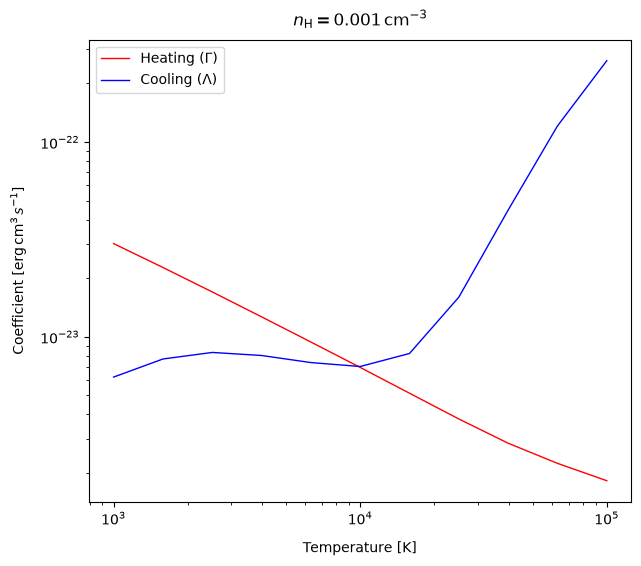

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.loglog(temperature[heating_mask], heating[heating_mask], color="red", linewidth=1, label=r"Heating ($\Gamma$)")
ax.loglog(temperature[cooling_mask], cooling[cooling_mask], color="blue", linewidth=1, label=r"Cooling ($\Lambda$)")

ax.set_xlabel(r"Temperature [${\rm K}$]", labelpad=10)
ax.set_ylabel(r"Coefficient [${\rm erg}\,{\rm cm}^{3}\,{s}^{-1}$]", labelpad=10)

ax.set_title(rf"$n_{{\rm H}}={selected_density}\,{{\rm cm}}^{{-3}}$", pad = 10)

ax.legend()

plt.show()

## 2. Ion fraction tables

The `IonTables` class combines individual Cloudy ionisation maps into an HDF5 file. The datasets contain logarithmic ion fractions with dimensions

$$
(N_{\mathrm{ions}},\ N_{\mathrm{density}},\ N_{\mathrm{redshift}},\ N_{\mathrm{temperature}})
$$

The original calculations are performed at $z = 0$. A second redshift coordinate, $z = 10^{-4}$, is introduced by duplicating the original data for compatibility with Trident (Hummels et al. 2017) interpolation. This duplication does not introduce new radiation physics or cosmological adjustments.

In [6]:
ib = IonTables(
    run_dir=IB_DIR,    # directory where the ion fraction outputs are
    run_name=RUN_NAME, # name of the calculations, must coincide with the files in run_dir
    elements="H C O",  # elements, must coincide with the elements calculated
)

# IonTables opens its HDF5 file in append mode
# Check the file doesn't exist before running this cell

if ib.outfile.exists():
    print("Using existing ionisation table:", ib.outfile)
else:
    ib.write_table()
    print("Prepared ionisation table:", ib.outfile)

Prepared ionisation table: /home/cphys/repos/py4radiation/notebooks/tutorial_runs/tutorial/ib/tutorial_iontable.h5


In [7]:
# Inspect the resulting HDF5 file
with h5py.File(ib.outfile, "r") as file:
    for element in file:
        dataset = file[element]

        print(f"\nElement: {element}")
        print("Dataset shape:", dataset.shape)

        for key, value in dataset.attrs.items():
            print(f"{key}: {value}")


Element: C
Dataset shape: (7, 2, 2, 11)
Parameter1: [-3. -2.]
Parameter2: [0.     0.0001]
Temperature: [3.  3.2 3.4 3.6 3.8 4.  4.2 4.4 4.6 4.8 5. ]

Element: H
Dataset shape: (2, 2, 2, 11)
Parameter1: [-3. -2.]
Parameter2: [0.     0.0001]
Temperature: [3.  3.2 3.4 3.6 3.8 4.  4.2 4.4 4.6 4.8 5. ]

Element: O
Dataset shape: (9, 2, 2, 11)
Parameter1: [-3. -2.]
Parameter2: [0.     0.0001]
Temperature: [3.  3.2 3.4 3.6 3.8 4.  4.2 4.4 4.6 4.8 5. ]


In [8]:
# Examine hydrogen ionisation
with h5py.File(ib.outfile, "r") as file:
    hydrogen = file["H"]
    log_ion_fraction = hydrogen[:]
    log_temperature = hydrogen.attrs["Temperature"]
    log_density = hydrogen.attrs["Parameter1"]
    redshift = hydrogen.attrs["Parameter2"]

print("Hydrogen dataset:", log_ion_fraction.shape)
print("Log density grid:", log_density)
print("Redshift grid:", redshift)
print("Log temperature grid:", log_temperature)

Hydrogen dataset: (2, 2, 2, 11)
Log density grid: [-3. -2.]
Redshift grid: [0.     0.0001]
Log temperature grid: [3.  3.2 3.4 3.6 3.8 4.  4.2 4.4 4.6 4.8 5. ]


In [9]:
# Verify the duplicated redshift axis
np.testing.assert_allclose(
    redshift,
    [0.0, 1.0e-4],
)

np.testing.assert_allclose(
    log_ion_fraction[:, :, 0, :],
    log_ion_fraction[:, :, 1, :],
)

print("The two redshift slices contain identical data.")

The two redshift slices contain identical data.


In [10]:
# Prepare data for hydrogen ion fractions
temperature = 10.0**log_temperature

# First density, original z=0 slice.
density_index = 0
redshift_index = 0

ion_labels = [r"H $_{\rm I}$", r"H $_{\rm II}$"]

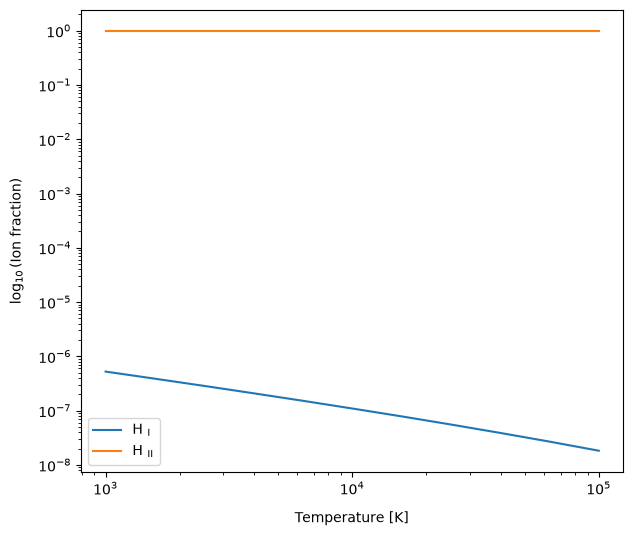

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))

for ion_index in range(log_ion_fraction.shape[0]):
    fraction = 10.0 ** log_ion_fraction[ion_index, density_index, redshift_index, :]

    ax.plot(temperature, fraction, label=ion_labels[ion_index])

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(r"Temperature [${\rm K}$]", labelpad=10)
ax.set_ylabel(r"$\log_{10}(\text{Ion fraction})$", labelpad=10)

ax.legend()

plt.show()

The resulting tables can be incorporated into subsequent astrophysical analysis and numerical simulation workflows. The scientific interpretation of the heating and cooling coefficients must always account for their density normalisation.